In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
SCRIPT_DIR = Path.cwd()
DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
if not DATA_PATH.exists():
    DATA_PATH = SCRIPT_DIR.parent / "USSeatBelts.csv"
def load_seatbelts():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {DATA_PATH.resolve()}. Put USSeatBelts.csv in this folder "
            "or change DATA_PATH at the top of this script."
        )
    return pd.read_csv(DATA_PATH)
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)
df = load_seatbelts()
show_data(df)


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    str    
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    str    
 7   speed70     765 non-null    str    
 8   drinkage    765 non-null    str    
 9   alcohol     765 non-null    str    
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    str    
dtypes: float64(3), int64(4), str(6)
memory usage: 77.8 KB

FIRST SIX ROWS:
    rownames state  year  miles  fatalitie

In [2]:
print("\nMISSING COUNTS\n", df.isna().sum())
print("\nMISSING PERCENTAGE\n", (df.isna().mean()*100).round(2))
print("\nROWS WITH MISSING VALUES\n", df[df.isna().any(axis=1)].head())
# Remove columns with more than 70% missing values.
clean = df.loc[:, df.isna().mean() <= .70].copy()
# Numeric imputations shown as separate strategies.
numeric_cols = clean.select_dtypes(include=np.number).columns
mean_data, median_data = clean.copy(), clean.copy()
for c in numeric_cols:
    if mean_data[c].isna().any() and mean_data[c].notna().any():
        mean_data[c] = mean_data[c].fillna(mean_data[c].mean())
    if median_data[c].isna().any() and median_data[c].notna().any():
        median_data[c] = median_data[c].fillna(median_data[c].median())
mode_data = clean.copy()
for c in mode_data.select_dtypes(exclude=np.number).columns:
    if mode_data[c].isna().any() and not mode_data[c].mode().empty:
        mode_data[c] = mode_data[c].fillna(mode_data[c].mode()[0])
print("\nMEAN IMPUTATION MISSING COUNTS\n", mean_data.isna().sum())
print("\nMEDIAN IMPUTATION MISSING COUNTS\n", median_data.isna().sum())
print("\nMODE IMPUTATION MISSING COUNTS\n", mode_data.isna().sum())
print("\nDUPLICATE ROW COUNT:", mode_data.duplicated().sum())
mode_data = mode_data.drop_duplicates()
print("ROWS AFTER DUPLICATE REMOVAL:", len(mode_data))
# Summary statistics for fatalities.
x = pd.to_numeric(mode_data.get("fatalities"), errors="coerce").dropna()


MISSING COUNTS
 rownames        0
state           0
year            0
miles           0
fatalities      0
seatbelt      209
speed65         0
speed70         0
drinkage        0
alcohol         0
income          0
age             0
enforce         0
dtype: int64

MISSING PERCENTAGE
 rownames       0.00
state          0.00
year           0.00
miles          0.00
fatalities     0.00
seatbelt      27.32
speed65        0.00
speed70        0.00
drinkage       0.00
alcohol        0.00
income         0.00
age            0.00
enforce        0.00
dtype: float64

ROWS WITH MISSING VALUES
    rownames state  year  miles  fatalities  seatbelt speed65 speed70 drinkage  \
0         1    AK  1983   3358    0.044669       NaN      no      no      yes   
1         2    AK  1984   3589    0.037336       NaN      no      no      yes   
2         3    AK  1985   3840    0.033073       NaN      no      no      yes   
3         4    AK  1986   4008    0.025200       NaN      no      no      yes   
4       


FATALITIES SUMMARY
 count    765.000000
mean       0.021490
std        0.006171
min        0.008327
25%        0.017341
50%        0.021199
75%        0.024774
max        0.045470
Name: fatalities, dtype: float64
Range: 0.037142787128686905 Variance: 3.808487554087269e-05 SD: 0.006171294478541167 IQR: 0.007433049380779301 Skewness: 0.7600253235279069 Kurtosis: 0.8113551489655251

SEATBELT FREQUENCY
 seatbelt
NaN      209
0.580     15
0.640     14
0.550     13
0.540     13
        ... 
0.709      1
0.765      1
0.840      1
0.820      1
0.559      1
Name: count, Length: 246, dtype: int64
SEATBELT RELATIVE FREQUENCY
 seatbelt
NaN      0.273203
0.580    0.019608
0.640    0.018301
0.550    0.016993
0.540    0.016993
           ...   
0.709    0.001307
0.765    0.001307
0.840    0.001307
0.820    0.001307
0.559    0.001307
Name: proportion, Length: 246, dtype: float64


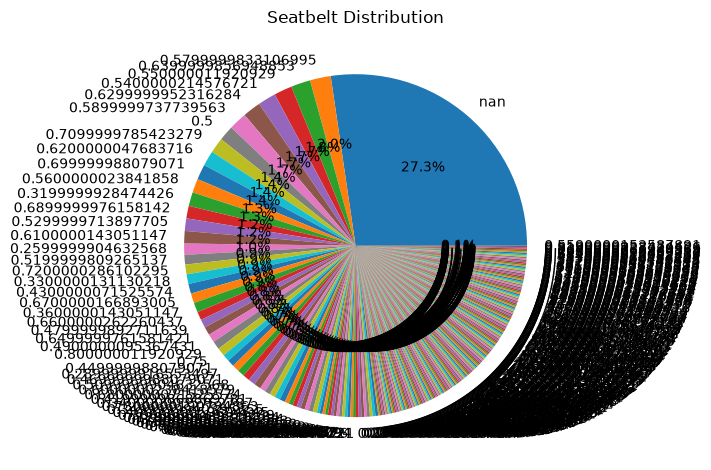

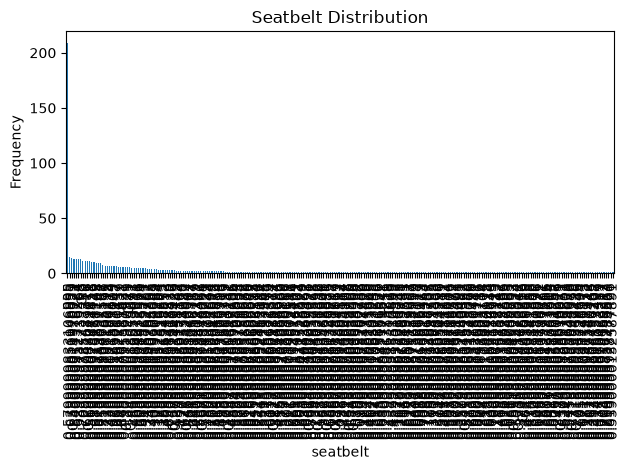


ALCOHOL FREQUENCY
 alcohol
no     676
yes     89
Name: count, dtype: int64
ALCOHOL RELATIVE FREQUENCY
 alcohol
no     0.88366
yes    0.11634
Name: proportion, dtype: float64

STATE FREQUENCY
 state
AK    15
AL    15
AR    15
AZ    15
CA    15
CO    15
CT    15
DC    15
DE    15
FL    15
GA    15
HI    15
IA    15
ID    15
IL    15
IN    15
KS    15
KY    15
LA    15
MA    15
MD    15
ME    15
MI    15
MN    15
MO    15
MS    15
MT    15
NC    15
ND    15
NE    15
NH    15
NJ    15
NM    15
NV    15
NY    15
OH    15
OK    15
OR    15
PA    15
RI    15
SC    15
SD    15
TN    15
TX    15
UT    15
VA    15
VT    15
WA    15
WI    15
WV    15
WY    15
Name: count, dtype: int64
STATE RELATIVE FREQUENCY
 state
AK    0.019608
AL    0.019608
AR    0.019608
AZ    0.019608
CA    0.019608
CO    0.019608
CT    0.019608
DC    0.019608
DE    0.019608
FL    0.019608
GA    0.019608
HI    0.019608
IA    0.019608
ID    0.019608
IL    0.019608
IN    0.019608
KS    0.019608
KY    0.019608
LA    0.019608

In [3]:
if len(x):
    print("\nFATALITIES SUMMARY\n", x.describe())
    print("Range:", x.max()-x.min(), "Variance:", x.var(), "SD:", x.std(),
          "IQR:", x.quantile(.75)-x.quantile(.25),
          "Skewness:", x.skew(), "Kurtosis:", x.kurtosis())
# Categorical frequency and relative frequency.
for col in ["seatbelt", "alcohol", "state"]:
    if col in mode_data:
        freq = mode_data[col].value_counts(dropna=False)
        print(f"\n{col.upper()} FREQUENCY\n", freq)
        print(f"{col.upper()} RELATIVE FREQUENCY\n", mode_data[col].value_counts(normalize=True, dropna=False))
        if col == "seatbelt":
            freq.plot(kind="pie", autopct="%1.1f%%", title="Seatbelt Distribution")
            plt.ylabel(""); plt.tight_layout(); plt.show()
            freq.plot(kind="bar", title="Seatbelt Distribution")
            plt.xlabel(col); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()


FATALITIES FREQUENCY TABLE
 fatalities
(0.00829, 0.012]     25
(0.012, 0.0158]     104
(0.0158, 0.0195]    190
(0.0195, 0.0232]    195
(0.0232, 0.0269]    121
(0.0269, 0.0306]     59
(0.0306, 0.0343]     45
(0.0343, 0.038]      16
(0.038, 0.0418]       6
(0.0418, 0.0455]      4
Name: count, dtype: int64


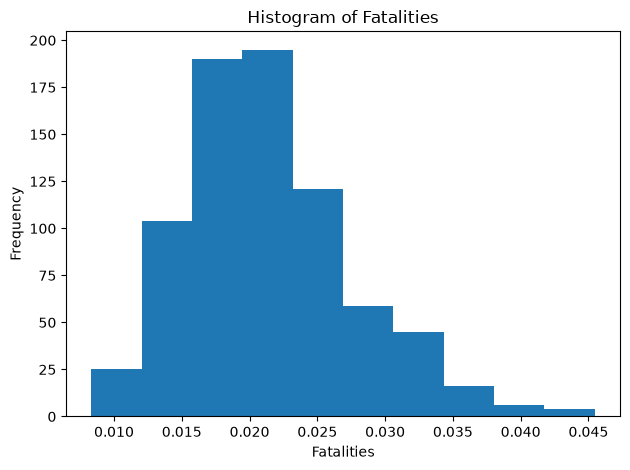

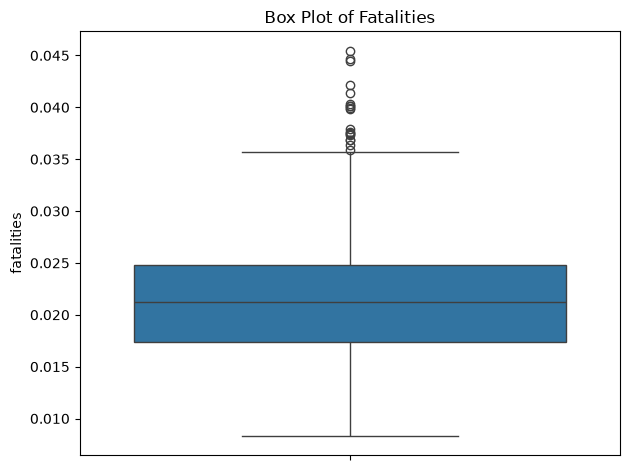

IQR LIMITS: 0.0061914660036562486 0.03592366352677345 
OUTLIER COUNT: 19


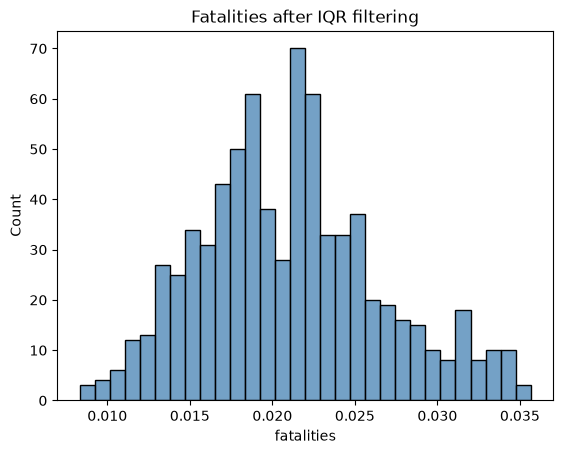

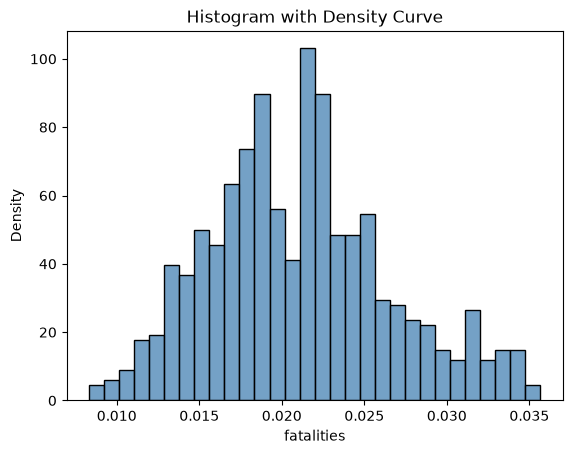

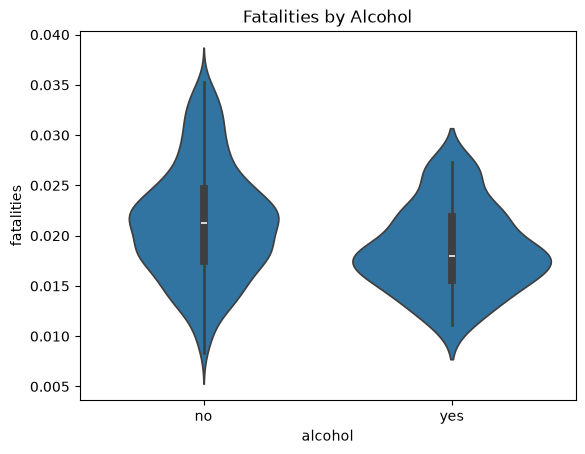

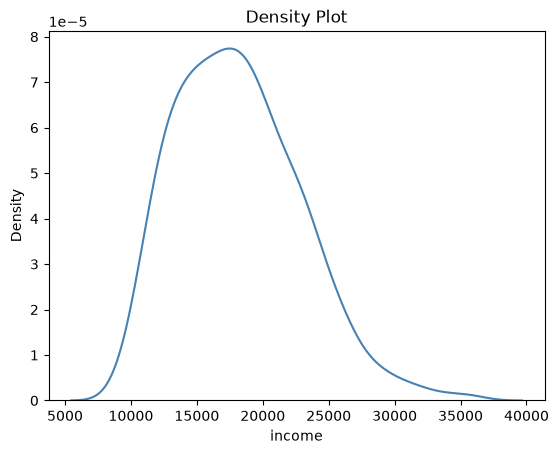


ALCOHOL PROPORTIONS
 alcohol
no     0.88366
yes    0.11634
Name: count, dtype: float64

ALCOHOL PERCENTAGES
 alcohol
no     88.366013
yes    11.633987
Name: count, dtype: float64


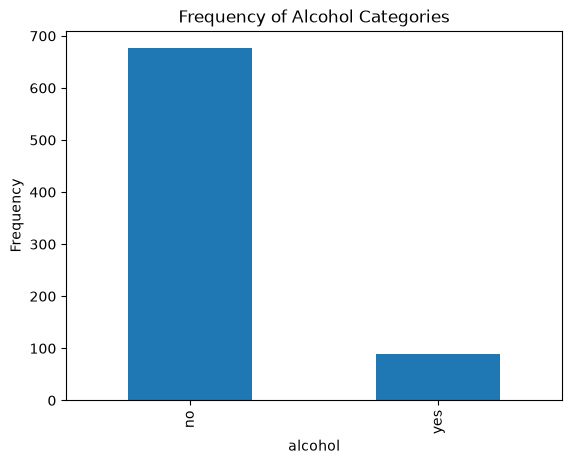

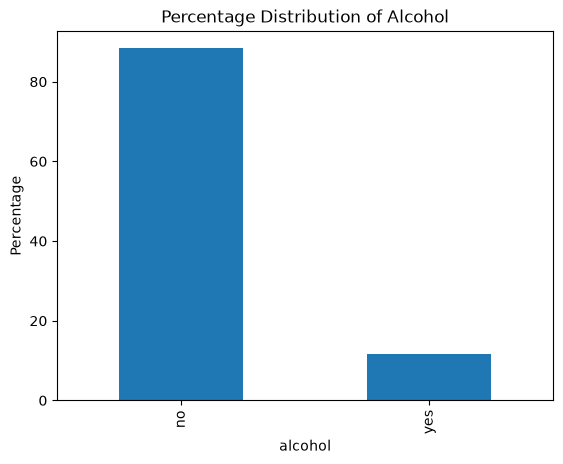

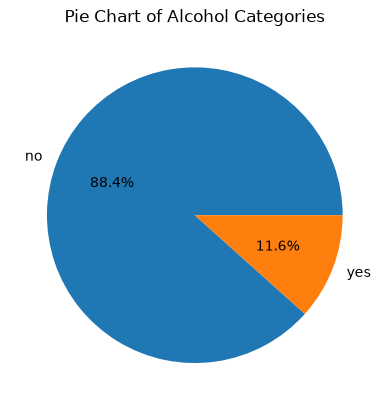

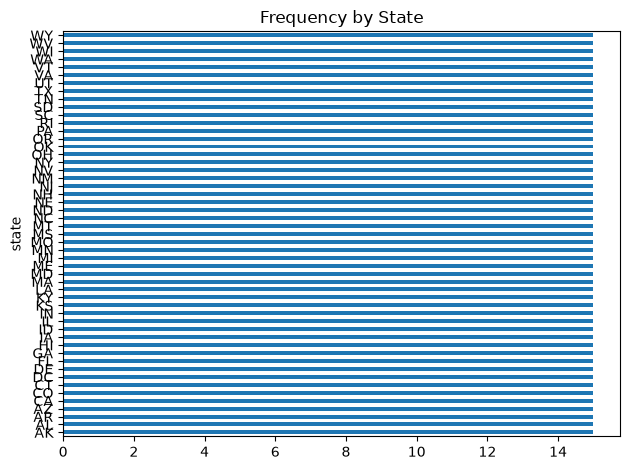

In [4]:
if len(x):
    print("\nFATALITIES FREQUENCY TABLE\n", pd.cut(x, bins=10).value_counts().sort_index())
    x.plot(kind="hist", bins=10, title="Histogram of Fatalities", xlabel="Fatalities")
    plt.tight_layout(); plt.show()
    sns.boxplot(y=x); plt.title("Box Plot of Fatalities"); plt.tight_layout(); plt.show()
    # IQR outlier detection and filtering
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3-q1
    low, high = q1-1.5*iqr, q3+1.5*iqr
    outliers = mode_data[(mode_data["fatalities"] < low) | (mode_data["fatalities"] > high)]
    print("IQR LIMITS:", low, high, "\nOUTLIER COUNT:", len(outliers))
    no_outliers = mode_data[mode_data["fatalities"].between(low, high)].copy()
    sns.histplot(no_outliers["fatalities"], bins=30, kde=False, color="steelblue"); plt.title("Fatalities after IQR filtering"); plt.show()
    sns.histplot(no_outliers["fatalities"], bins=30, stat="density", kde=False, color="steelblue"); plt.title("Histogram with Density Curve"); plt.show()
    if "alcohol" in no_outliers:
        sns.violinplot(data=no_outliers, x="alcohol", y="fatalities"); plt.title("Fatalities by Alcohol"); plt.show()
    sns.kdeplot(data=no_outliers, x="income" if "income" in no_outliers else "fatalities", color="steelblue", fill=False); plt.title("Density Plot"); plt.show()
# Proportion/percentage and charts for categorical variables.
if "alcohol" in mode_data:
    counts = mode_data["alcohol"].value_counts()
    print("\nALCOHOL PROPORTIONS\n", counts/counts.sum())
    print("\nALCOHOL PERCENTAGES\n", counts/counts.sum()*100)
    counts.plot(kind="bar", title="Frequency of Alcohol Categories"); plt.ylabel("Frequency"); plt.show()
    (counts/counts.sum()*100).plot(kind="bar", title="Percentage Distribution of Alcohol"); plt.ylabel("Percentage"); plt.show()
    counts.plot(kind="pie", autopct="%1.1f%%", title="Pie Chart of Alcohol Categories"); plt.ylabel(""); plt.show()
if "state" in mode_data:
    mode_data["state"].value_counts().sort_values().plot(kind="barh", title="Frequency by State")
    plt.tight_layout(); plt.show()


UPPERCASE TEXT SAMPLE
    rownames state  year  miles  fatalities  seatbelt speed65 speed70 drinkage  \
0         1    AK  1983   3358    0.044669       NaN      NO      NO      YES   
1         2    AK  1984   3589    0.037336       NaN      NO      NO      YES   
2         3    AK  1985   3840    0.033073       NaN      NO      NO      YES   
3         4    AK  1986   4008    0.025200       NaN      NO      NO      YES   
4         5    AK  1987   3900    0.019487       NaN      NO      NO      YES   

  alcohol  income        age enforce  
0      NO   17973  28.234966      NO  
1      NO   18093  28.343542      NO  
2      NO   18925  28.372816      NO  
3      NO   18466  28.396652      NO  
4      NO   18021  28.453251      NO  


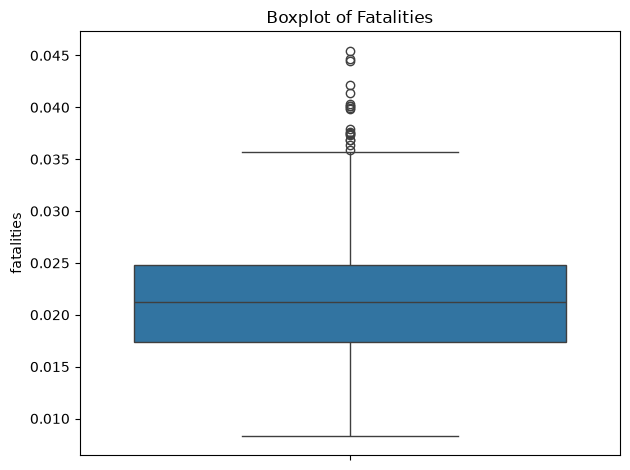

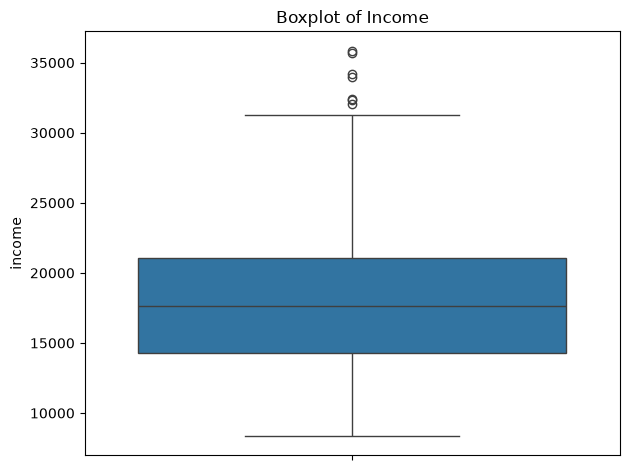

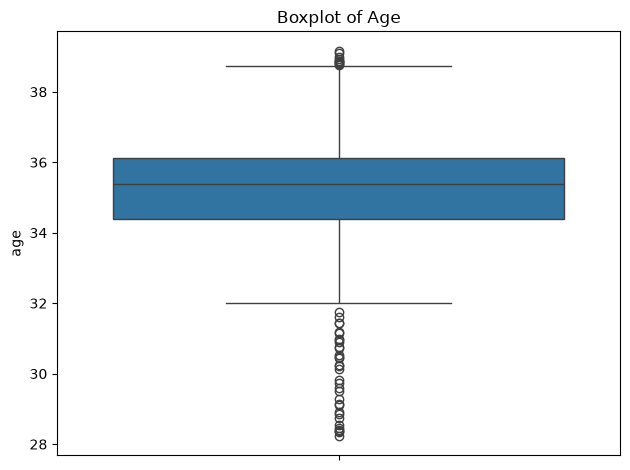

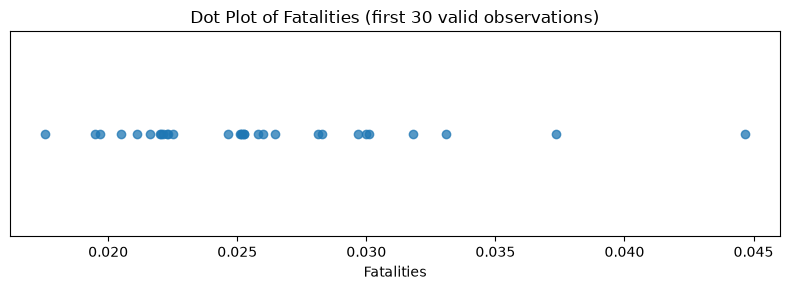

In [5]:
# Additional transformations and plots represented in the original lab.
# Uppercase text values (demonstrated on a separate copy).
upper_data = mode_data.copy()
for c in upper_data.select_dtypes(include="object").columns:
    upper_data[c] = upper_data[c].str.upper()
print("\nUPPERCASE TEXT SAMPLE\n", upper_data.head())
# Boxplots and IQR outlier analysis for several numerical variables.
for col in ["fatalities", "income", "age"]:
    if col in mode_data:
        sns.boxplot(y=pd.to_numeric(mode_data[col], errors="coerce"))
        plt.title(f"Boxplot of {col.title()}")
        plt.tight_layout()
        plt.show()
# Small-sample dot plot equivalent.
if "fatalities" in mode_data:
    small = pd.to_numeric(mode_data["fatalities"], errors="coerce").dropna().head(30)
    plt.figure(figsize=(8,3))
    plt.scatter(small, np.zeros(len(small)), alpha=.75)
    plt.yticks([])
    plt.xlabel("Fatalities")
    plt.title("Dot Plot of Fatalities (first 30 valid observations)")
    plt.tight_layout()
    plt.show()

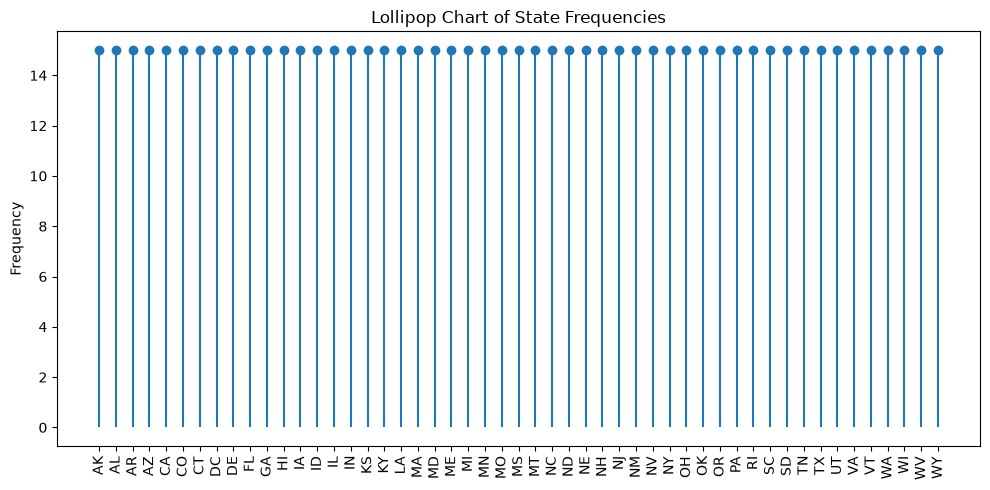

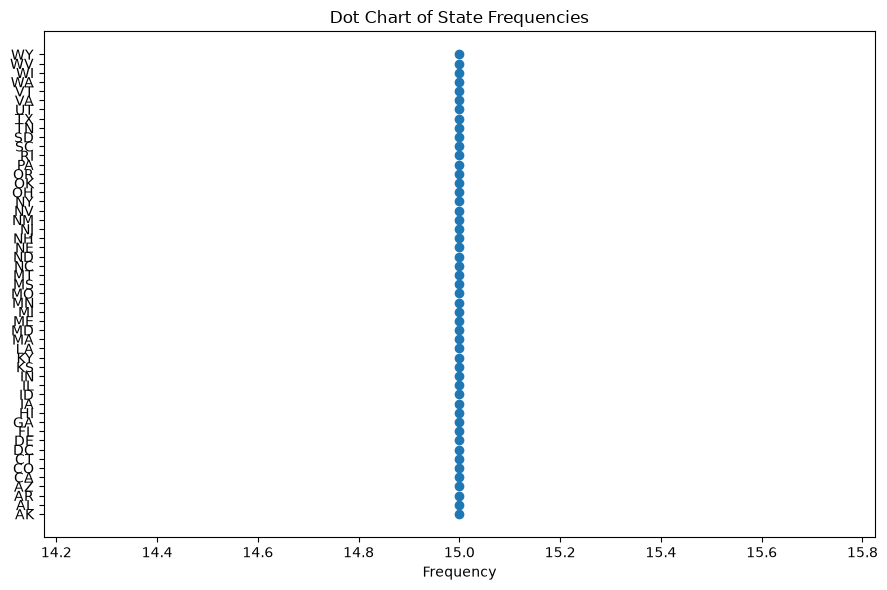

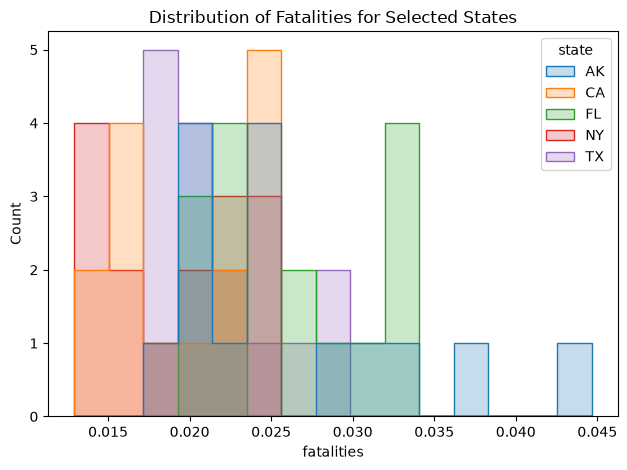

In [6]:
# Lollipop and dot charts of state frequencies.
if "state" in mode_data:
    state_freq = mode_data["state"].value_counts().sort_values()
    plt.figure(figsize=(10,5))
    plt.vlines(range(len(state_freq)), 0, state_freq.values)
    plt.scatter(range(len(state_freq)), state_freq.values)
    plt.xticks(range(len(state_freq)), state_freq.index, rotation=90)
    plt.title("Lollipop Chart of State Frequencies")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    state_freq.plot(kind="scatter", x=None, y=None) if False else None
    plt.figure(figsize=(9,6))
    plt.scatter(state_freq.values, state_freq.index)
    plt.title("Dot Chart of State Frequencies")
    plt.xlabel("Frequency")
    plt.tight_layout()
    plt.show()
# Compare fatality distributions for a few states, if present.
if {"state", "fatalities"}.issubset(mode_data.columns):
    chosen = mode_data[mode_data["state"].astype(str).isin(["AK", "CA", "NY", "TX", "FL"])]
    if not chosen.empty:
        sns.histplot(data=chosen, x="fatalities", hue="state", bins=15, element="step", stat="count", common_norm=False)
        plt.title("Distribution of Fatalities for Selected States")
        plt.tight_layout()
        plt.show()